# 1D Chebyshev interpolation

This notebook shows the basic ChebyshevND workflow in one dimension:

1. sample your function at **Chebyshev nodes** on the domain of interest,
2. build a `ChebyshevInterpolant1D` from the sampled values,
3. evaluate it anywhere in the domain.

For smooth functions the interpolant converges *spectrally*: the error decays
exponentially with the number of nodes. We use the classic Runge function
$f(x) = 1/(1 + 25x^2)$, which famously defeats equally-spaced polynomial
interpolation but is easy prey for Chebyshev nodes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from chebyshevnd import (
    ChebyshevInterpolant1D,
    chebyshev_nodes,
    chebyshev_gauss_lobatto_nodes,
)

In [2]:
f = lambda x: 1.0 / (1.0 + 25 * x**2)
a, b = -1.0, 1.0
N = 100

# Sample f at the N Chebyshev (root) nodes of [a, b], in the order returned,
# and build the interpolant with the same (a, b) pair
x_nodes = chebyshev_nodes(N, a, b)
interp = ChebyshevInterpolant1D(f(x_nodes), a=a, b=b)

**Keep the node order.** `chebyshev_nodes(N, a, b)` returns the nodes in
*descending* order (from `b` to `a`), and the coefficient computation assumes
the values arrive in that order. Sample at the nodes exactly as returned —
don't sort them — and pass the same `(a, b)` pair to the interpolant.

Be careful when testing with a symmetric function on a symmetric domain, like
the Runge function here: reversing the node order reflects the interpolant,
and for an even function on $[-1, 1]$ that mistake is invisible.

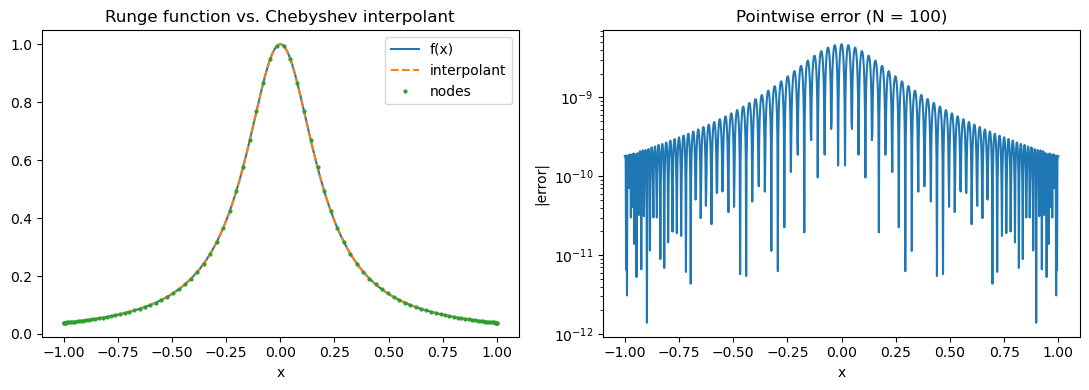

In [3]:
x_test = np.linspace(a, b, 1001)
y_interp = interp.evaluate(x_test)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(x_test, f(x_test), label="f(x)")
ax1.plot(x_test, y_interp, "--", label="interpolant")
ax1.plot(x_nodes, f(x_nodes), ".", ms=4, label="nodes")
ax1.set_xlabel("x")
ax1.legend()
ax1.set_title("Runge function vs. Chebyshev interpolant")

ax2.semilogy(x_test, np.abs(y_interp - f(x_test)))
ax2.set_xlabel("x")
ax2.set_ylabel("|error|")
ax2.set_title(f"Pointwise error (N = {N})")
plt.tight_layout()
plt.show()

## Coefficient decay and error estimates

The Chebyshev coefficients of a smooth function decay geometrically, and the
magnitude of the trailing coefficients estimates the interpolation error —
no extra function samples needed.

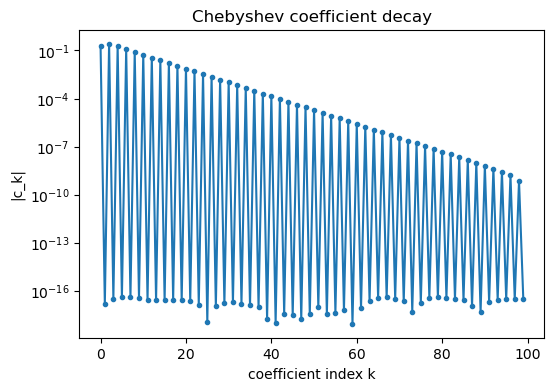

estimated absolute error: 7.519e-10
measured  absolute error: 4.699e-09
estimated relative error: 2.852e-09


In [4]:
coeffs = interp.get_coefficients()

plt.figure(figsize=(6, 4))
plt.semilogy(np.abs(coeffs), ".-")
plt.xlabel("coefficient index k")
plt.ylabel("|c_k|")
plt.title("Chebyshev coefficient decay")
plt.show()

measured = np.max(np.abs(interp.evaluate(x_test) - f(x_test)))
print(f"estimated absolute error: {interp.absolute_error():.3e}")
print(f"measured  absolute error: {measured:.3e}")
print(f"estimated relative error: {interp.relative_error():.3e}")

## Gauss–Lobatto nodes

If you need the domain endpoints included in the sample grid (for example when
the values come from a solver that provides boundary data), sample at
Chebyshev–Gauss–Lobatto nodes and pass `nodes='GaussLobatto'`. Both node
families give equivalent interpolants for well-resolved functions.

In [5]:
x_gl = chebyshev_gauss_lobatto_nodes(N, a, b)
interp_gl = ChebyshevInterpolant1D(f(x_gl), a=a, b=b, nodes="GaussLobatto")

print("endpoints included:", x_gl[-1] == a and x_gl[0] == b)
diff = np.max(np.abs(interp_gl.evaluate(x_test) - interp.evaluate(x_test)))
print(f"max difference between the two interpolants: {diff:.3e}")

endpoints included: True
max difference between the two interpolants: 9.216e-10


## Truncating the series with `optimize`

`optimize(rel_tol)` drops trailing coefficients that are insignificant at the
requested relative tolerance, shortening every subsequent evaluation. The
truncation is recorded in `k_max` (the number of coefficients used).

In [6]:
print(f"coefficients used before: {interp.k_max}")
interp.optimize(rel_tol=1e-6)
print(f"coefficients used after:  {interp.k_max}")

err_after = np.max(np.abs(interp.evaluate(x_test) - f(x_test)))
print(f"max error after truncation: {err_after:.3e}")

coefficients used before: 100
coefficients used after:  71
max error after truncation: 7.326e-07


## Spectral convergence

Interpolation error versus the number of nodes, on a log scale: the straight
line is the signature of geometric (spectral) convergence.

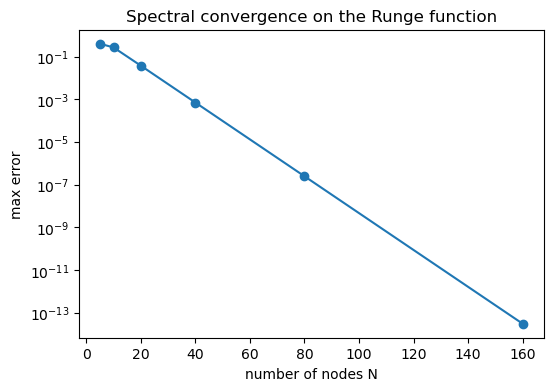

In [7]:
Ns = [5, 10, 20, 40, 80, 160]
errors = []
for n in Ns:
    xi = chebyshev_nodes(n, a, b)
    itp = ChebyshevInterpolant1D(f(xi), a=a, b=b)
    errors.append(np.max(np.abs(itp.evaluate(x_test) - f(x_test))))

plt.figure(figsize=(6, 4))
plt.semilogy(Ns, errors, "o-")
plt.xlabel("number of nodes N")
plt.ylabel("max error")
plt.title("Spectral convergence on the Runge function")
plt.show()